In [15]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from cuml.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score,confusion_matrix,ConfusionMatrixDisplay,roc_curve,roc_auc_score,accuracy_score,classification_report,f1_score,precision_score,recall_score,precision_recall_curve

import matplotlib.pyplot as plt
import seaborn as sns


In [16]:
data = pd.read_csv("/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv")
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [17]:
data.info()
print(data.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [18]:
data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


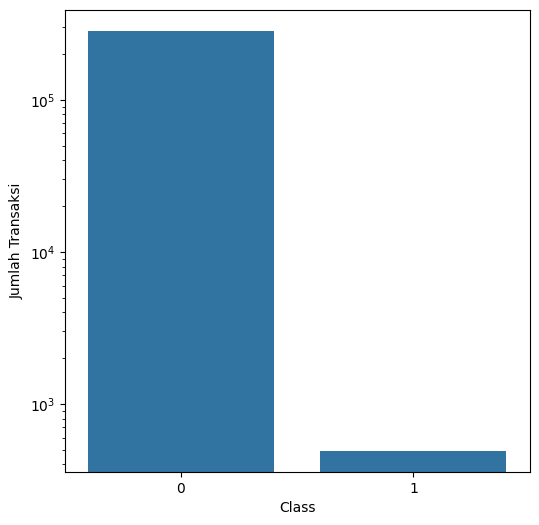

In [19]:
class_count = data["Class"].value_counts().sort_index()
class_percentage = data["Class"].value_counts(normalize=True).sort_index() * 100

print(class_count)
print(class_percentage.round(4))

plt.figure(figsize=(6,6))
sns.countplot(data=data,x="Class")
plt.yscale("log")
plt.xlabel("Class")
plt.ylabel("Jumlah Transaksi")
plt.show()

In [20]:
X = data.drop("Class",axis = 1)
Y = data["Class"]

X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size = 0.2,stratify=Y,random_state=42)

print(Y_train.value_counts().sort_index())
print(Y_test.value_counts().sort_index())

Class
0    227451
1       394
Name: count, dtype: int64
Class
0    56864
1       98
Name: count, dtype: int64


In [21]:
fitur =[c for c in X.columns]
fitur


['Time',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'Amount']

In [22]:
preprocessor = ColumnTransformer([
    ("scale", StandardScaler(),fitur)
])

RFC_default = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier())
])
RFC_Imbalance = Pipeline([
    ("preprocess", preprocessor),
    ("SMOTE", SMOTE(random_state = 42)),
    ("model", RandomForestClassifier())
])

CatBoost_default = Pipeline([
    ("preprocess", preprocessor),
    ("model", CatBoostClassifier(task_type = "GPU"))
])
CatBoost_Imbalance = Pipeline([
    ("preprocess", preprocessor),
    ("SMOTE", SMOTE(random_state = 42)),
    ("model", CatBoostClassifier(task_type = "GPU"))
])

XGBoost_default = Pipeline([
    ("preprocess", preprocessor),
    ("model", XGBClassifier(tree_method = "hist", device = "cuda"))
])
XGBoost_Imbalance = Pipeline([
    ("preprocess", preprocessor),
    ("SMOTE", SMOTE(random_state = 42)),
    ("model", XGBClassifier(tree_method = "hist", device = "cuda"))
])


In [23]:
RFC_default.fit(X_train,Y_train)
y_pred_default = RFC_default.predict(X_test)
y_score_default = RFC_default.predict_proba(X_test)[:, 1]
score_default = average_precision_score(Y_test,y_score_default)
print(score_default)
confusion_matrix(Y_test,y_pred_default)

0.8847580791385342


array([[56863,     1],
       [   20,    78]])

In [24]:
RFC_Imbalance.fit(X_train,Y_train)
y_pred_Imbalance = RFC_Imbalance.predict(X_test)
y_score_Imbalance = RFC_Imbalance.predict_proba(X_test)[:, 1]
score_Imbalance = average_precision_score(Y_test,y_score_Imbalance)
print(score_Imbalance)
confusion_matrix(Y_test,y_pred_Imbalance)

0.8574516066024069


array([[56828,    36],
       [   16,    82]])

In [25]:
CatBoost_default.fit(X_train,Y_train)
y_pred_CatBoost = CatBoost_default.predict(X_test)
y_score_CatBoost = CatBoost_default.predict_proba(X_test)[:, 1]
score_CatBoost = average_precision_score(Y_test,y_score_CatBoost)
print(score_CatBoost)
confusion_matrix(Y_test,y_pred_CatBoost)


Learning rate set to 0.025009
0:	learn: 0.5976814	total: 47.4ms	remaining: 47.3s
1:	learn: 0.5132317	total: 58ms	remaining: 28.9s
2:	learn: 0.4393968	total: 68.5ms	remaining: 22.8s
3:	learn: 0.3755808	total: 78.8ms	remaining: 19.6s
4:	learn: 0.3210387	total: 88.7ms	remaining: 17.7s
5:	learn: 0.2746782	total: 98.9ms	remaining: 16.4s
6:	learn: 0.2356927	total: 109ms	remaining: 15.5s
7:	learn: 0.2018096	total: 120ms	remaining: 14.9s
8:	learn: 0.1727330	total: 130ms	remaining: 14.4s
9:	learn: 0.1471322	total: 141ms	remaining: 13.9s
10:	learn: 0.1267161	total: 151ms	remaining: 13.6s
11:	learn: 0.1094588	total: 161ms	remaining: 13.3s
12:	learn: 0.0957004	total: 172ms	remaining: 13.1s
13:	learn: 0.0831039	total: 183ms	remaining: 12.9s
14:	learn: 0.0725979	total: 193ms	remaining: 12.7s
15:	learn: 0.0636760	total: 204ms	remaining: 12.5s
16:	learn: 0.0558879	total: 214ms	remaining: 12.4s
17:	learn: 0.0488433	total: 224ms	remaining: 12.2s
18:	learn: 0.0428335	total: 234ms	remaining: 12.1s
19:	lea

array([[56860,     4],
       [   18,    80]])

In [26]:
CatBoost_Imbalance.fit(X_train,Y_train)
y_pred_CatBoost_Imbalance = CatBoost_Imbalance.predict(X_test)
y_score_CatBoost_Imbalance = CatBoost_Imbalance.predict_proba(X_test)[:, 1]
score_CatBoost_Imbalance = average_precision_score(Y_test,y_score_CatBoost_Imbalance)
print(score_CatBoost_Imbalance)
confusion_matrix(Y_test,y_pred_CatBoost_Imbalance)


Learning rate set to 0.024076
0:	learn: 0.6445673	total: 9.03ms	remaining: 9.02s
1:	learn: 0.6027979	total: 16.7ms	remaining: 8.32s
2:	learn: 0.5585528	total: 24.2ms	remaining: 8.05s
3:	learn: 0.5184648	total: 32.6ms	remaining: 8.11s
4:	learn: 0.4807369	total: 40.5ms	remaining: 8.07s
5:	learn: 0.4473092	total: 48.7ms	remaining: 8.06s
6:	learn: 0.4228840	total: 56.8ms	remaining: 8.06s
7:	learn: 0.3995157	total: 64.8ms	remaining: 8.03s
8:	learn: 0.3777751	total: 72.9ms	remaining: 8.03s
9:	learn: 0.3524813	total: 80.9ms	remaining: 8.01s
10:	learn: 0.3346684	total: 89ms	remaining: 8s
11:	learn: 0.3138002	total: 97.3ms	remaining: 8.01s
12:	learn: 0.3004509	total: 105ms	remaining: 8s
13:	learn: 0.2859658	total: 113ms	remaining: 7.98s
14:	learn: 0.2745366	total: 121ms	remaining: 7.96s
15:	learn: 0.2619423	total: 129ms	remaining: 7.95s
16:	learn: 0.2508403	total: 137ms	remaining: 7.95s
17:	learn: 0.2402937	total: 146ms	remaining: 7.96s
18:	learn: 0.2310877	total: 154ms	remaining: 7.95s
19:	lea

array([[56793,    71],
       [   14,    84]])

In [27]:
XGBoost_default.fit(X_train,Y_train)
y_pred_XGBoost = XGBoost_default.predict(X_test)
y_score_XGBoost = XGBoost_default.predict_proba(X_test)[:, 1]
score_XGBoost = average_precision_score(Y_test,y_score_XGBoost)
print(score_XGBoost)
confusion_matrix(Y_test,y_pred_XGBoost)


0.7759017629865979


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [11:52:01] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


array([[56855,     9],
       [   20,    78]])

In [28]:
XGBoost_Imbalance.fit(X_train,Y_train)
y_pred_XGBoost_Imbalance = XGBoost_Imbalance.predict(X_test)
y_score_XGBoost_Imbalance = XGBoost_Imbalance.predict_proba(X_test)[:, 1]
score_XGBoost_Imbalance = average_precision_score(Y_test,y_score_XGBoost_Imbalance)
print(score_XGBoost_Imbalance)
confusion_matrix(Y_test,y_pred_XGBoost_Imbalance)


0.8671487093067971


array([[56832,    32],
       [   14,    84]])

In [29]:
results = pd.DataFrame({
    "Model": ["Random Forest", "Random Forest + SMOTE", "CatBoost", "CatBoost + SMOTE", "XGBoost", "XGBoost + SMOTE"],
    "Precision": [
        precision_score(Y_test,y_pred_default,zero_division=0),
        precision_score(Y_test,y_pred_Imbalance,zero_division=0),
        precision_score(Y_test,y_pred_CatBoost,zero_division=0),
        precision_score(Y_test,y_pred_CatBoost_Imbalance,zero_division=0),
        precision_score(Y_test,y_pred_XGBoost,zero_division=0),
        precision_score(Y_test,y_pred_XGBoost_Imbalance,zero_division=0)
    ],
    "Recall": [
        recall_score(Y_test,y_pred_default,zero_division=0),
        recall_score(Y_test,y_pred_Imbalance,zero_division=0),
        recall_score(Y_test,y_pred_CatBoost,zero_division=0),
        recall_score(Y_test,y_pred_CatBoost_Imbalance,zero_division=0),
        recall_score(Y_test,y_pred_XGBoost,zero_division=0),
        recall_score(Y_test,y_pred_XGBoost_Imbalance,zero_division=0)
    ],
    "F1-score": [
        f1_score(Y_test,y_pred_default,zero_division=0),
        f1_score(Y_test,y_pred_Imbalance,zero_division=0),
        f1_score(Y_test,y_pred_CatBoost,zero_division=0),
        f1_score(Y_test,y_pred_CatBoost_Imbalance,zero_division=0),
        f1_score(Y_test,y_pred_XGBoost,zero_division=0),
        f1_score(Y_test,y_pred_XGBoost_Imbalance,zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(Y_test,y_score_default),
        roc_auc_score(Y_test,y_score_Imbalance),
        roc_auc_score(Y_test,y_score_CatBoost),
        roc_auc_score(Y_test,y_score_CatBoost_Imbalance),
        roc_auc_score(Y_test,y_score_XGBoost),
        roc_auc_score(Y_test,y_score_XGBoost_Imbalance)
    ],
    "Average Precision": [score_default,score_Imbalance,score_CatBoost,score_CatBoost_Imbalance,score_XGBoost,score_XGBoost_Imbalance],
    "Accuracy": [
        accuracy_score(Y_test,y_pred_default),
        accuracy_score(Y_test,y_pred_Imbalance),
        accuracy_score(Y_test,y_pred_CatBoost),
        accuracy_score(Y_test,y_pred_CatBoost_Imbalance),
        accuracy_score(Y_test,y_pred_XGBoost),
        accuracy_score(Y_test,y_pred_XGBoost_Imbalance)
    ]
})
results


,Model,Precision,Recall,F1-score,ROC-AUC,Average Precision,Accuracy
0,Random Forest,0.987342,0.795918,0.881356,0.970676,0.884758,0.999631
1,Random Forest + SMOTE,0.694915,0.836735,0.759259,0.983979,0.857452,0.999087
2,CatBoost,0.952381,0.816327,0.879121,0.980622,0.881434,0.999614
3,CatBoost + SMOTE,0.541935,0.857143,0.664032,0.980175,0.850152,0.998508
4,XGBoost,0.896552,0.795918,0.843243,0.922011,0.775902,0.999491
5,XGBoost + SMOTE,0.724138,0.857143,0.785047,0.983318,0.867149,0.999192


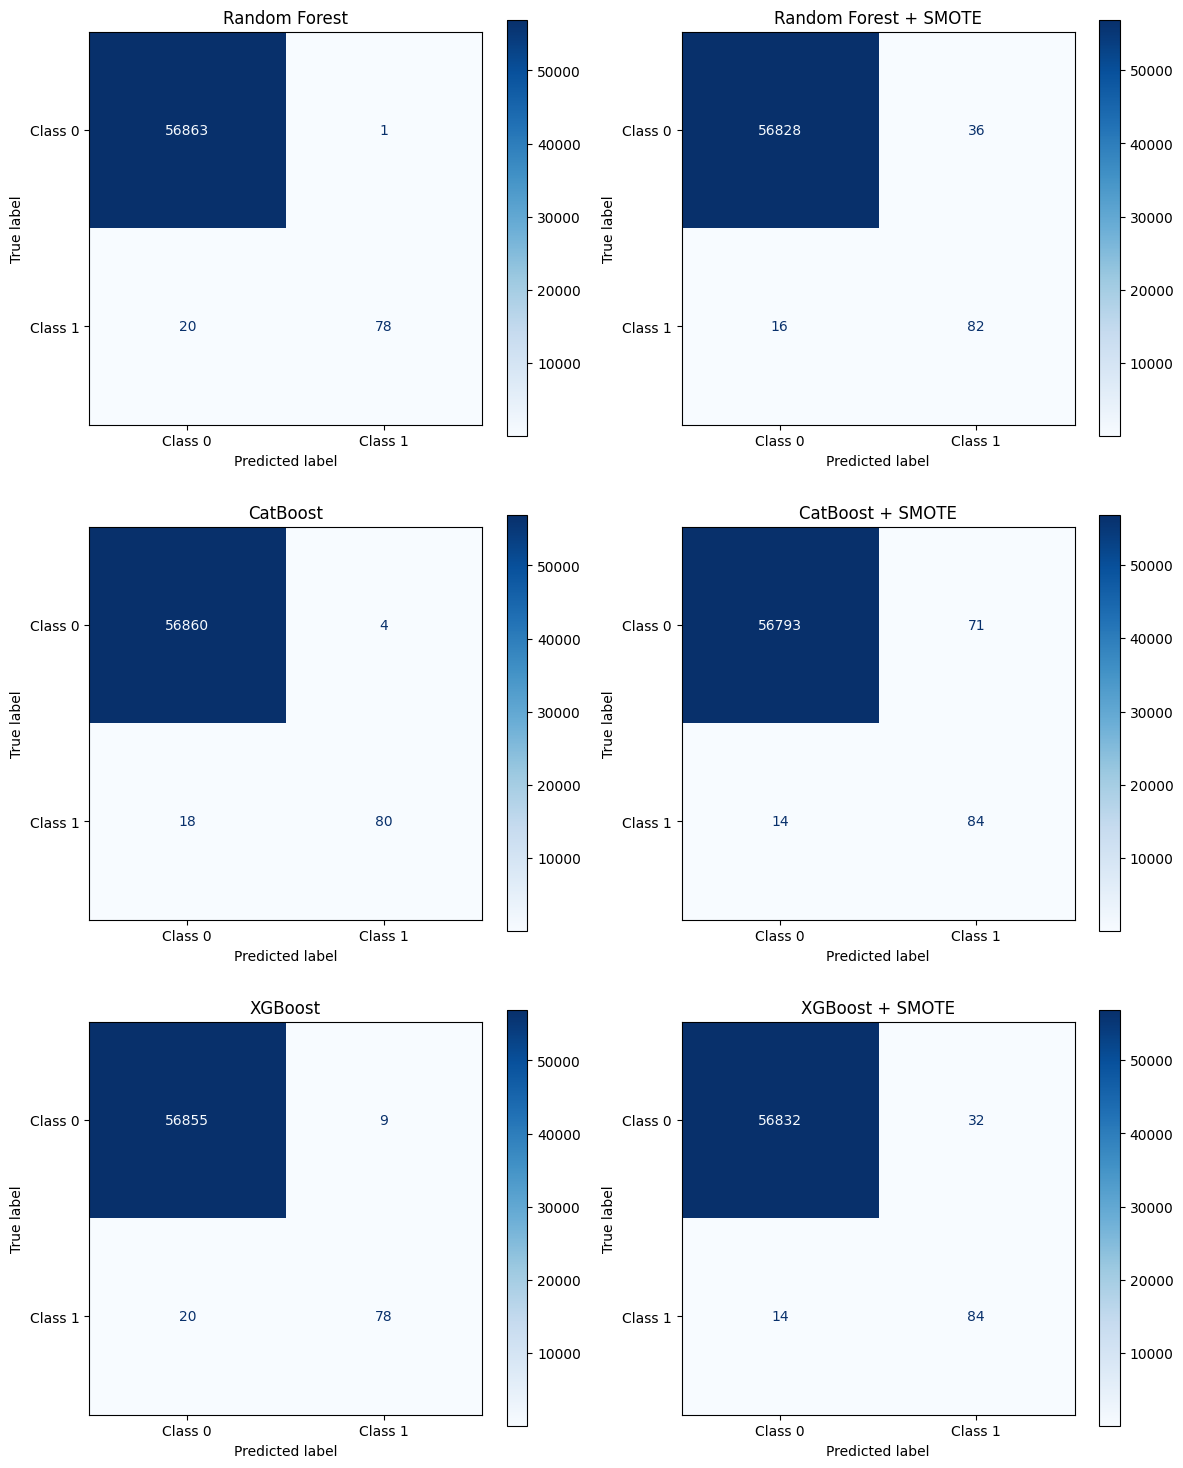

In [30]:
fig, axes = plt.subplots(3,2,figsize=(12,15))

ConfusionMatrixDisplay.from_predictions(Y_test,y_pred_default,display_labels=["Class 0", "Class 1"],cmap=plt.cm.Blues,ax=axes[0,0])
axes[0,0].set_title("Random Forest")

ConfusionMatrixDisplay.from_predictions(Y_test,y_pred_Imbalance,display_labels=["Class 0", "Class 1"],cmap=plt.cm.Blues,ax=axes[0,1])
axes[0,1].set_title("Random Forest + SMOTE")

ConfusionMatrixDisplay.from_predictions(Y_test,y_pred_CatBoost,display_labels=["Class 0", "Class 1"],cmap=plt.cm.Blues,ax=axes[1,0])
axes[1,0].set_title("CatBoost")

ConfusionMatrixDisplay.from_predictions(Y_test,y_pred_CatBoost_Imbalance,display_labels=["Class 0", "Class 1"],cmap=plt.cm.Blues,ax=axes[1,1])
axes[1,1].set_title("CatBoost + SMOTE")

ConfusionMatrixDisplay.from_predictions(Y_test,y_pred_XGBoost,display_labels=["Class 0", "Class 1"],cmap=plt.cm.Blues,ax=axes[2,0])
axes[2,0].set_title("XGBoost")

ConfusionMatrixDisplay.from_predictions(Y_test,y_pred_XGBoost_Imbalance,display_labels=["Class 0", "Class 1"],cmap=plt.cm.Blues,ax=axes[2,1])
axes[2,1].set_title("XGBoost + SMOTE")

plt.tight_layout()
plt.show()


In [31]:
print("Random Forest")
print(classification_report(Y_test,y_pred_default,target_names=["Normal", "Fraud"],digits=4,zero_division=0))

print("Random Forest + SMOTE")
print(classification_report(Y_test,y_pred_Imbalance,target_names=["Normal", "Fraud"],digits=4,zero_division=0))

print("CatBoost")
print(classification_report(Y_test,y_pred_CatBoost,target_names=["Normal", "Fraud"],digits=4,zero_division=0))

print("CatBoost + SMOTE")
print(classification_report(Y_test,y_pred_CatBoost_Imbalance,target_names=["Normal", "Fraud"],digits=4,zero_division=0))

print("XGBoost")
print(classification_report(Y_test,y_pred_XGBoost,target_names=["Normal", "Fraud"],digits=4,zero_division=0))

print("XGBoost + SMOTE")
print(classification_report(Y_test,y_pred_XGBoost_Imbalance,target_names=["Normal", "Fraud"],digits=4,zero_division=0))


Random Forest
              precision    recall  f1-score   support

      Normal     0.9996    1.0000    0.9998     56864
       Fraud     0.9873    0.7959    0.8814        98

    accuracy                         0.9996     56962
   macro avg     0.9935    0.8980    0.9406     56962
weighted avg     0.9996    0.9996    0.9996     56962

Random Forest + SMOTE
              precision    recall  f1-score   support

      Normal     0.9997    0.9994    0.9995     56864
       Fraud     0.6949    0.8367    0.7593        98

    accuracy                         0.9991     56962
   macro avg     0.8473    0.9181    0.8794     56962
weighted avg     0.9992    0.9991    0.9991     56962

CatBoost
              precision    recall  f1-score   support

      Normal     0.9997    0.9999    0.9998     56864
       Fraud     0.9524    0.8163    0.8791        98

    accuracy                         0.9996     56962
   macro avg     0.9760    0.9081    0.9395     56962
weighted avg     0.9996    0.

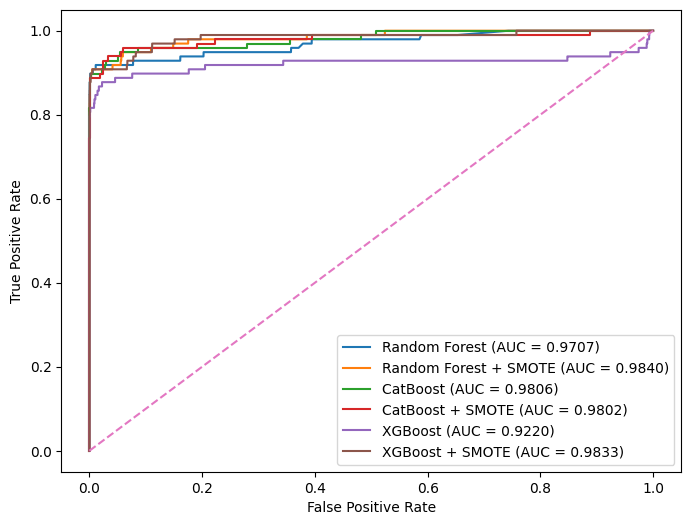

In [32]:
fpr_default,tpr_default,_ = roc_curve(Y_test,y_score_default)
fpr_Imbalance,tpr_Imbalance,_ = roc_curve(Y_test,y_score_Imbalance)
fpr_CatBoost,tpr_CatBoost,_ = roc_curve(Y_test,y_score_CatBoost)
fpr_CatBoost_Imbalance,tpr_CatBoost_Imbalance,_ = roc_curve(Y_test,y_score_CatBoost_Imbalance)
fpr_XGBoost,tpr_XGBoost,_ = roc_curve(Y_test,y_score_XGBoost)
fpr_XGBoost_Imbalance,tpr_XGBoost_Imbalance,_ = roc_curve(Y_test,y_score_XGBoost_Imbalance)

plt.figure(figsize=(8,6))
plt.plot(fpr_default,tpr_default,label=f"Random Forest (AUC = {roc_auc_score(Y_test,y_score_default):.4f})")
plt.plot(fpr_Imbalance,tpr_Imbalance,label=f"Random Forest + SMOTE (AUC = {roc_auc_score(Y_test,y_score_Imbalance):.4f})")
plt.plot(fpr_CatBoost,tpr_CatBoost,label=f"CatBoost (AUC = {roc_auc_score(Y_test,y_score_CatBoost):.4f})")
plt.plot(fpr_CatBoost_Imbalance,tpr_CatBoost_Imbalance,label=f"CatBoost + SMOTE (AUC = {roc_auc_score(Y_test,y_score_CatBoost_Imbalance):.4f})")
plt.plot(fpr_XGBoost,tpr_XGBoost,label=f"XGBoost (AUC = {roc_auc_score(Y_test,y_score_XGBoost):.4f})")
plt.plot(fpr_XGBoost_Imbalance,tpr_XGBoost_Imbalance,label=f"XGBoost + SMOTE (AUC = {roc_auc_score(Y_test,y_score_XGBoost_Imbalance):.4f})")
plt.plot([0,1],[0,1],linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


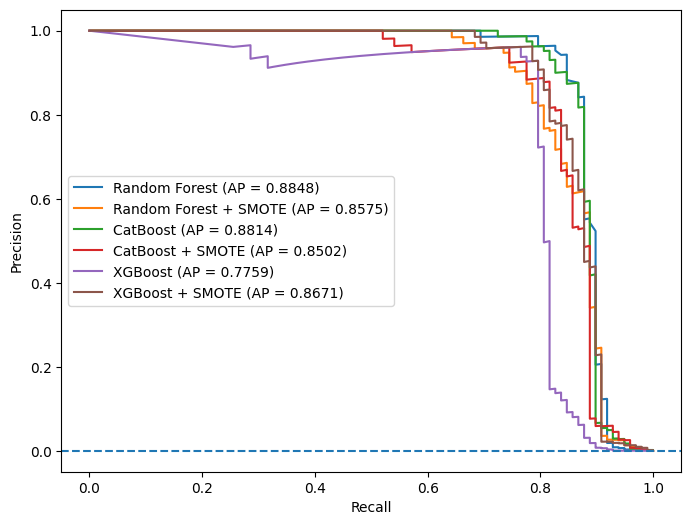

In [33]:
precision_default,recall_default,_ = precision_recall_curve(Y_test,y_score_default)
precision_Imbalance,recall_Imbalance,_ = precision_recall_curve(Y_test,y_score_Imbalance)
precision_CatBoost,recall_CatBoost,_ = precision_recall_curve(Y_test,y_score_CatBoost)
precision_CatBoost_Imbalance,recall_CatBoost_Imbalance,_ = precision_recall_curve(Y_test,y_score_CatBoost_Imbalance)
precision_XGBoost,recall_XGBoost,_ = precision_recall_curve(Y_test,y_score_XGBoost)
precision_XGBoost_Imbalance,recall_XGBoost_Imbalance,_ = precision_recall_curve(Y_test,y_score_XGBoost_Imbalance)

plt.figure(figsize=(8,6))
plt.plot(recall_default,precision_default,label=f"Random Forest (AP = {score_default:.4f})")
plt.plot(recall_Imbalance,precision_Imbalance,label=f"Random Forest + SMOTE (AP = {score_Imbalance:.4f})")
plt.plot(recall_CatBoost,precision_CatBoost,label=f"CatBoost (AP = {score_CatBoost:.4f})")
plt.plot(recall_CatBoost_Imbalance,precision_CatBoost_Imbalance,label=f"CatBoost + SMOTE (AP = {score_CatBoost_Imbalance:.4f})")
plt.plot(recall_XGBoost,precision_XGBoost,label=f"XGBoost (AP = {score_XGBoost:.4f})")
plt.plot(recall_XGBoost_Imbalance,precision_XGBoost_Imbalance,label=f"XGBoost + SMOTE (AP = {score_XGBoost_Imbalance:.4f})")
plt.axhline(y=Y_test.mean(),linestyle="--")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()
